![Banner](../images/09_13_banner_rs_soil_moisture.png)

# Soil Moisture: Concepts and Why It Matters

Soil moisture is a small store of water, a few percent of the fresh water on land, but it
controls how rain is split between runoff and infiltration, how the sun's energy is split between
evaporation and heating the air, and how much water a crop can draw on between rains. This first
notebook of the chapter sets out the quantities the rest of the chapter measures from space,
using two public in situ stations in central Iowa: ten years of hourly readings at five depths
from the US Climate Reference Network (USCRN) and daily readings from the Soil Climate Analysis
Network (SCAN). It then estimates the water holding limits of the soils below the stations from
SoilGrids texture with the Saxton and Rawls (2006) pedotransfer functions, and uses them to show
when the root zone ran short of water.

## Overview

### Ways to express soil water

| Quantity | Definition | Units |
|---|---|---|
| Gravimetric water content `w` | mass of water / mass of dry soil | g g-1 |
| Volumetric water content `theta` | volume of water / volume of soil, `theta = w rho_b / rho_w` | m3 m-3 |
| Porosity `phi` | pore volume / soil volume, `1 - rho_b / rho_s` | m3 m-3 |
| Degree of saturation `s` | `theta / phi`, 0 (dry) to 1 (saturated) | 1 or % |
| Field capacity `FC` | water held after free drainage, about -33 kPa | m3 m-3 |
| Wilting point `WP` | water held so tightly that plants cannot extract it, -1500 kPa | m3 m-3 |
| Plant available water `PAW` | `FC - WP` | m3 m-3 |

Satellites and most sensors report volumetric water content. Some products (ASCAT, the ESA CCI
ACTIVE record) report the degree of saturation instead, which needs porosity to convert; crop
models think in available water between wilting point and field capacity.

### Surface and root zone

Microwave sensors see the top few centimetres (about 5 cm at L-band, 1 to 2 cm at C- and X-band),
while crops draw water from the top metre. The surface layer reacts to every shower and dries
within days; deeper layers respond to the sum of many events. Chapter notebooks 05 and 24 come
back to this gap between what is sensed and what matters to plants.

### Why it matters

- **Water cycle**: wet soils produce more runoff from the same rain; dry soils store it.
- **Energy cycle**: evaporation from moist soil cools the surface; dry soil heats the air and can
  intensify heat waves (land-atmosphere coupling).
- **Carbon cycle**: photosynthesis and soil respiration both slow down when water runs short.
- **Hazards and agriculture**: drought, flood potential, landslides, fire danger and crop yield all
  depend on the water stored in the soil.

### Measuring soil moisture in situ

| Method | Principle | Footprint |
|---|---|---|
| Gravimetric sampling | weigh, oven dry at 105 C, weigh again | a core of a few cm, destructive |
| Time domain reflectometry (TDR) | travel time of a pulse along rods gives the apparent permittivity; the Topp et al. (1980) equation converts it to `theta` | about 10 cm around the rods |
| Capacitance and impedance probes | permittivity from the frequency or impedance of a circuit (USCRN and SCAN use Stevens HydraProbes) | a few cm |
| Cosmic-ray neutron sensing (COSMOS) | fast neutrons from cosmic rays are slowed by hydrogen in soil water | about 150 m radius, 10 to 50 cm deep |
| GNSS reflectometry | change of reflected GPS signal with soil permittivity | tens of metres |

Point sensors measure a few cubic centimetres; a satellite pixel averages kilometres. This scale
gap is the main difficulty of validation (notebooks 21 to 23).

## Soil Water with GeoLattice

| Function | Purpose |
|---|---|
| `sm.read_uscrn`, `sm.read_scan` (through `sd.uscrn`, `sd.scan`) | public in situ networks, no account |
| `sm.load_soilgrids` (through `sd.soilgrids_profile`) | SoilGrids 2.0 texture, carbon and bulk density |
| `sm.saxton_rawls`, `sm.porosity_from_texture` | wilting point, field capacity, saturation, ksat |
| `sm.volumetric_from_gravimetric`, `sm.degree_of_saturation`, `sm.saturation_to_volumetric` | unit conversions |
| `sm.soil_water_status` | relative available water between WP and FC |
| `sm.topp`, `sm.topp_inverse` | TDR calibration equation |

### Learning objectives

1. Convert between gravimetric, volumetric and relative measures of soil water.
2. Read and plot multi-depth in situ soil moisture and see how a storm's wetting front moves down.
3. Compare two sensor networks and recognize sensor artefacts.
4. Estimate wilting point, field capacity and porosity from texture with pedotransfer functions.
5. Track plant available water in the root zone through ten seasons.

### Data

| Dataset | Content |
|---|---|
| USCRN Des Moines 17 E (`IA_Des_Moines_17_E`), 2015 to 2025 | hourly soil moisture at 5, 10, 20, 50 and 100 cm, soil temperature, precipitation |
| SCAN 2031 Ames, 2015 to 2025 | daily soil moisture at 5, 10, 20, 51 and 102 cm (2 to 40 inch sensors) |
| SoilGrids 2.0 at both stations | sand, silt, clay, organic carbon and bulk density at six depths |

### Contents

- Setup
- Ten years of soil moisture at five depths
- How a storm wets the profile
- Two stations, two networks
- Soil texture from SoilGrids
- Water holding limits from texture
- Plant available water in the root zone
- Unit conversions and the Topp equation
- Summary and exercises

## Setup

In [1]:
import warnings  # warning control
warnings.filterwarnings("ignore")  # hide routine library warnings
from pathlib import Path  # file paths

import matplotlib.pyplot as plt  # figures
import numpy as np  # arrays
import pandas as pd  # tables
import rioxarray  # noqa: F401  (registers the .rio accessor)
import xarray as xr  # labelled rasters

import geolattice  # GeoLattice
import geolattice.rsense.soil_moisture as sm  # soil moisture physics, products, retrieval and validation
import sm_data as sd  # chapter helper: subsets, downloads and caches the data

plt.rcParams.update({"figure.dpi": 110})  # figure resolution
OUT = Path("outputs")  # results written by this chapter
OUT.mkdir(exist_ok=True)  # create it if needed
print("GeoLattice", geolattice.__version__, "| data folder", sd.DATA.relative_to(sd.DATA.parents[3]))  # versions and paths

uscrn = sd.uscrn()  # hourly USCRN record (UTC)
scan = sd.scan()  # daily SCAN record
prof = {st: sd.soilgrids_profile(st) for st in sd.STATIONS.index}  # SoilGrids profiles under both stations
DEPTHS = [5, 10, 20, 50, 100]  # USCRN sensor depths (cm)
print(f"USCRN: {len(uscrn):,} hours from {uscrn.index.min():%Y-%m-%d} to {uscrn.index.max():%Y-%m-%d}; "
      f"SCAN: {len(scan):,} days")  # record lengths
display(sd.STATIONS)  # station locations

GeoLattice 0.3.49 | data folder GeoLattice/Data/08_remote_sensing/08_13_soil_moisture
USCRN: 96,432 hours from 2015-01-01 to 2025-12-31; SCAN: 4,018 days


,network,id,lon,lat
station,,,,
USCRN Des Moines 17 E,USCRN,IA_Des_Moines_17_E,-93.28610,41.5564
SCAN Ames,SCAN,2031:IA:SCAN,-93.72977,42.0136


## Ten years of soil moisture at five depths

The USCRN sensors report the mean of each hour. Daily means are enough to see the seasons; the
missing winter values are frozen soil, when the probes do not measure liquid water.

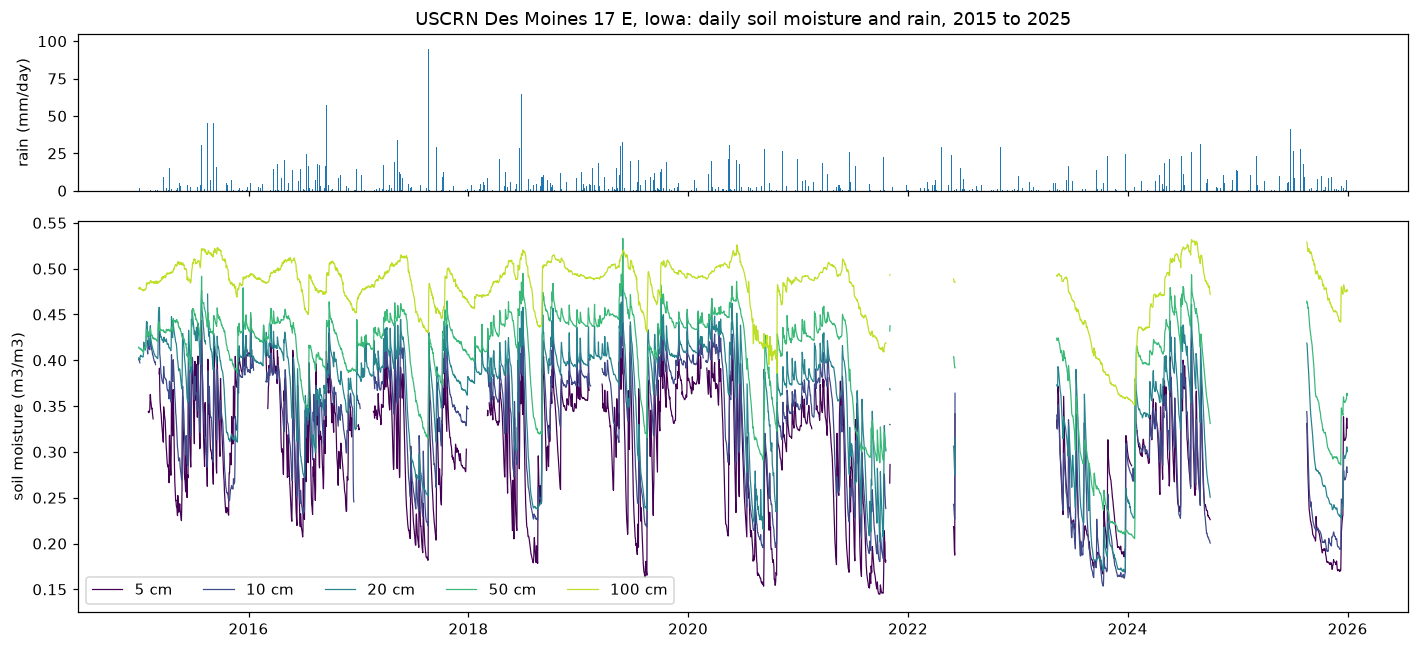

,count,mean,std,2%,50%,98%
5 cm,2817.0,0.296,0.069,0.162,0.306,0.406
10 cm,2902.0,0.321,0.069,0.173,0.338,0.418
20 cm,3133.0,0.360,0.067,0.184,0.384,0.443
50 cm,3139.0,0.404,0.059,0.221,0.426,0.469
100 cm,3139.0,0.479,0.034,0.371,0.489,0.521


In [2]:
daily = uscrn.resample("1D").mean()  # daily means of the hourly values
daily["p_mm"] = uscrn["p_mm"].resample("1D").sum(min_count=1)  # daily precipitation total
fig, ax = plt.subplots(2, 1, figsize=(13, 6), sharex=True, gridspec_kw={"height_ratios": [1, 2.5]})  # rain and soil
ax[0].bar(daily.index, daily.p_mm, width=1, color="tab:blue"); ax[0].set_ylabel("rain (mm/day)")  # precipitation
for d, c in zip(DEPTHS, plt.cm.viridis(np.linspace(0, 0.9, 5))):  # one line per depth
    ax[1].plot(daily.index, daily[f"sm_{d}"], color=c, lw=0.8, label=f"{d} cm")  # daily soil moisture
ax[1].set_ylabel("soil moisture (m3/m3)"); ax[1].legend(ncol=5, loc="lower left")  # labels
ax[0].set_title("USCRN Des Moines 17 E, Iowa: daily soil moisture and rain, 2015 to 2025"); plt.tight_layout(); plt.show()  # draw
stats = pd.DataFrame({f"{d} cm": daily[f"sm_{d}"].describe(percentiles=[0.02, 0.5, 0.98]) for d in DEPTHS}).T  # distribution per depth
display(stats[["count", "mean", "std", "2%", "50%", "98%"]].round(3))  # summary table

The surface layers swing widely and quickly, between about 0.16 and 0.41 m3 m-3 (2nd and 98th
percentiles at 5 cm), while the 100 cm sensor stays near 0.48 to 0.52 and only drops in the dry
late summers of 2020, 2021 and 2023. Mean soil moisture rises with depth (0.30 at 5 cm, 0.48 at
100 cm) in this silty clay loam and the standard deviation halves: the deep sensors integrate many
rain events. Winters are missing (frozen soil), and the record has a long outage from late 2021 to
spring 2023, a reminder that in situ series have gaps too.

## How a storm wets the profile

The wettest day of 2024 at the station was 2 July. The hourly record shows how the water entered
the profile.

,before,peak,rise,hours_to_peak
depth_cm,,,,
5,0.336,0.459,0.123,12.0
10,0.353,0.451,0.098,12.0
20,0.406,0.499,0.093,12.0
50,0.457,0.514,0.057,11.0
100,0.520,0.529,0.009,12.0


rain from 2024-07-02 09:00 UTC: 83 mm in the window


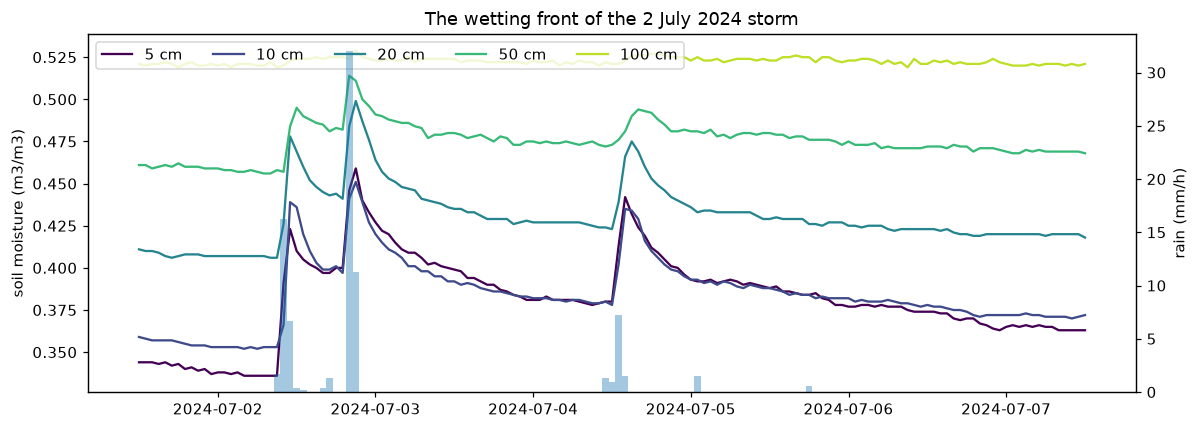

In [3]:
t0 = pd.Timestamp("2024-07-01 12:00")  # before the storm (UTC)
win = uscrn.loc[t0:t0 + pd.Timedelta(days=6)]  # six days of hourly data
rain_start = win.index[win.p_mm > 0.5][0]  # first hour with rain
rows = []  # response of each depth
for d in DEPTHS:  # each sensor
    s = win[f"sm_{d}"]  # hourly series
    before = float(s.loc[:rain_start].iloc[-3:].mean())  # value just before the rain
    peak_t = s.idxmax()  # time of the maximum
    rows.append({"depth_cm": d, "before": before, "peak": float(s.max()), "rise": float(s.max()) - before,
                 "hours_to_peak": (peak_t - rain_start).total_seconds() / 3600})  # rise and delay
resp = pd.DataFrame(rows).set_index("depth_cm")  # one row per depth
display(resp.round(3))  # response table
fig, ax = plt.subplots(figsize=(11, 4))  # hourly plot
for d, c in zip(DEPTHS, plt.cm.viridis(np.linspace(0, 0.9, 5))):  # one line per depth
    ax.plot(win.index, win[f"sm_{d}"], color=c, label=f"{d} cm")  # hourly soil moisture
ax2 = ax.twinx(); ax2.bar(win.index, win.p_mm, width=1 / 24, color="tab:blue", alpha=0.4); ax2.set_ylabel("rain (mm/h)")  # rain
ax.set_ylabel("soil moisture (m3/m3)"); ax.legend(ncol=5, loc="upper left")  # labels
print(f"rain from {rain_start:%Y-%m-%d %H:%M} UTC: {win.p_mm.sum():.0f} mm in the window")  # storm total
ax.set_title("The wetting front of the 2 July 2024 storm"); plt.tight_layout(); plt.show()  # draw

About 83 mm fell in two bursts on 2 July and a third on 4 July. Every sensor down to 50 cm rose
within the same hour as the rain and peaked about 12 hours after it started, so the water did not
move down as a slow front: in this clay-rich soil it bypassed the matrix through cracks and root
channels (preferential flow). The size of the rise, however, shrinks with depth, from 0.12 m3 m-3 at
5 cm to 0.06 at 50 cm and almost nothing at 100 cm, which was already near saturation. Between storms
the surface layers dry fastest. A satellite sees only the top of this column, which is why its
retrievals look much more variable than what a crop experiences.

## Two stations, two networks

SCAN Ames lies about 60 km north-west of the USCRN station. Both use HydraProbe sensors but different
installations and calibrations.

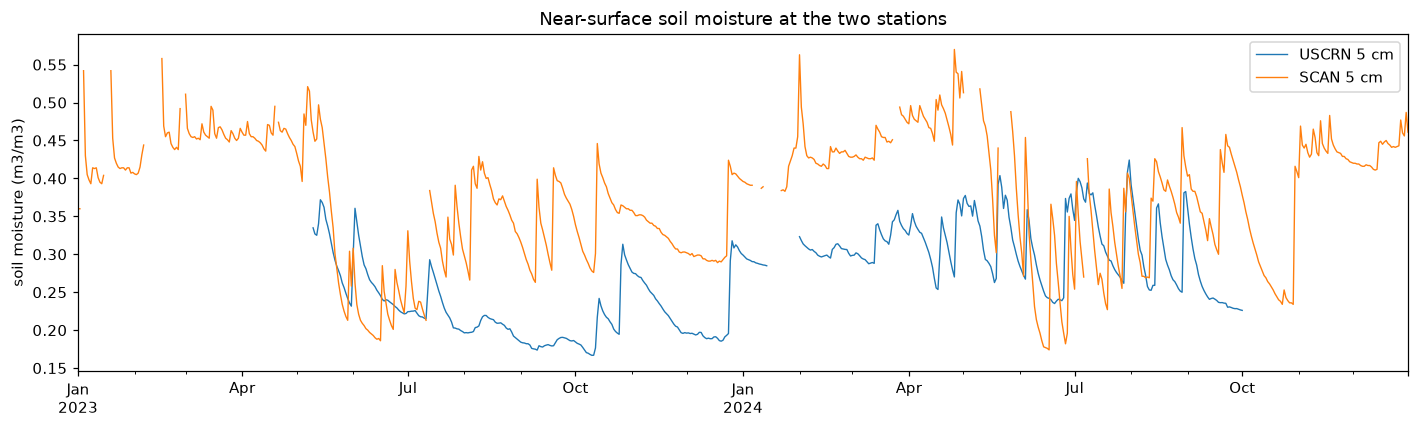

correlation of daily values:
             SCAN 5 cm  SCAN 51 cm
USCRN 5 cm        0.43        0.34
USCRN 50 cm       0.15        0.39
SCAN 5 cm days above 0.55 m3/m3: 11 of 3909


In [4]:
both = pd.DataFrame({"USCRN 5 cm": daily["sm_5"], "SCAN 5 cm": scan["sm_5"],
                     "USCRN 50 cm": daily["sm_50"], "SCAN 51 cm": scan["sm_51"]}).loc["2015":"2025"]  # daily series
fig, ax = plt.subplots(figsize=(13, 4))  # time series
both.loc["2023":"2024", ["USCRN 5 cm", "SCAN 5 cm"]].plot(ax=ax, lw=0.9)  # two recent years
ax.set_ylabel("soil moisture (m3/m3)"); ax.set_title("Near-surface soil moisture at the two stations"); plt.tight_layout(); plt.show()  # draw
print("correlation of daily values:")  # agreement
print(both.corr().round(2).loc[["USCRN 5 cm", "USCRN 50 cm"], ["SCAN 5 cm", "SCAN 51 cm"]])  # cross-correlations
high = (scan["sm_5"] > 0.55).sum()  # days above any plausible porosity
print(f"SCAN 5 cm days above 0.55 m3/m3: {high} of {scan['sm_5'].notnull().sum()}")  # sensor artefacts

The two series share the seasonal drying and the largest storms, but their daily correlation is
only 0.43 at 5 cm and 0.39 at 50 cm: rain falls differently 60 km apart, the soils differ, and so
do the installations. On 11 days the SCAN 5 cm sensor reports more than 0.55 m3 m-3, above any
plausible porosity of a loam; these are sensor artefacts (for example water ponding around the
probe), and validation in notebook 21 screens such values out. Two stations in one region are not
interchangeable at the daily scale, which is the first hint of the point-to-pixel problem.

## Soil texture from SoilGrids

SoilGrids 2.0 (Poggio et al. 2021) predicts soil properties at 250 m from soil profiles and
covariates with machine learning. `sd.soilgrids_profile` reads its six standard depths under each
station through `sm.load_soilgrids`, which fetches only a small window of the global mosaics.

In [5]:
for st, p in prof.items():  # each station
    print(st)  # header
    display(p.round(3))  # sand, silt, clay as fractions, soc in g/kg, bdod in g/cm3

USCRN Des Moines 17 E


,sand,silt,clay,soc,bdod
depth,,,,,
0-5cm,0.153,0.514,0.333,30.6,1.38
5-15cm,0.152,0.512,0.336,18.8,1.55
15-30cm,0.144,0.487,0.370,12.1,1.56
30-60cm,0.140,0.497,0.363,6.0,1.61
60-100cm,0.148,0.482,0.371,3.5,1.68
100-200cm,0.165,0.490,0.344,2.3,1.70


SCAN Ames


,sand,silt,clay,soc,bdod
depth,,,,,
0-5cm,0.256,0.446,0.298,19.1,1.49
5-15cm,0.254,0.442,0.304,31.6,1.61
15-30cm,0.263,0.448,0.289,18.9,1.62
30-60cm,0.279,0.437,0.284,9.9,1.66
60-100cm,0.312,0.432,0.256,3.0,1.72
100-200cm,0.463,0.359,0.179,0.8,1.72


Under the USCRN station SoilGrids predicts a silty clay loam with 33 to 37 % clay and about 50 %
silt at every depth; under SCAN Ames a clay loam with about 30 % clay near the surface that becomes
loamier and sandier below a metre (glacial till). Organic carbon is highest in the top 30 cm.

## Water holding limits from texture

Saxton and Rawls (2006) fitted regressions of the water held at -33 and -1500 kPa on sand, clay
and organic matter, using about 2,000 US soil samples. `sm.saxton_rawls` returns wilting point,
field capacity, saturation (porosity), plant available water, normal bulk density and saturated
hydraulic conductivity. Organic matter is about 1.72 times organic carbon.

In [6]:
ptf = {}  # pedotransfer results per station
for st, p in prof.items():  # each station
    om = 0.1724 * p["soc"]  # organic matter (%) from organic carbon (g/kg): OM = 1.724 SOC
    r = sm.saxton_rawls(p["sand"].values, p["clay"].values, organic_matter=om.values)  # pedotransfer functions
    ptf[st] = pd.DataFrame({k: np.asarray(v) for k, v in r.items()}, index=p.index)  # one row per depth
    print(st); display(ptf[st].round(3))  # table
obs = pd.DataFrame({"2%": [daily[f"sm_{d}"].quantile(0.02) for d in DEPTHS],
                    "98%": [daily[f"sm_{d}"].quantile(0.98) for d in DEPTHS]},
                   index=[f"{d} cm" for d in DEPTHS])  # observed range at USCRN
print("USCRN observed range, 2015 to 2025:"); display(obs.round(3))  # compare with WP and saturation

USCRN Des Moines 17 E


,wilting_point,field_capacity,saturation,plant_available_water,bulk_density,lambda_,ksat
depth,,,,,,,
0-5cm,0.215,0.383,0.560,0.168,1.167,0.070,12.022
5-15cm,0.211,0.375,0.516,0.164,1.281,0.069,6.320
15-30cm,0.225,0.381,0.498,0.156,1.330,0.063,3.538
30-60cm,0.219,0.376,0.478,0.157,1.383,0.065,2.357
60-100cm,0.223,0.377,0.471,0.154,1.402,0.063,1.859
100-200cm,0.207,0.363,0.457,0.156,1.438,0.067,1.873


SCAN Ames


,wilting_point,field_capacity,saturation,plant_available_water,bulk_density,lambda_,ksat
depth,,,,,,,
0-5cm,0.192,0.349,0.499,0.157,1.329,0.071,7.347
5-15cm,0.204,0.366,0.546,0.162,1.204,0.070,12.657
15-30cm,0.188,0.345,0.497,0.157,1.334,0.073,7.714
30-60cm,0.179,0.329,0.459,0.151,1.434,0.073,4.865
60-100cm,0.158,0.302,0.423,0.144,1.528,0.076,4.036
100-200cm,0.109,0.230,0.392,0.120,1.612,0.084,9.577


USCRN observed range, 2015 to 2025:


,2%,98%
5 cm,0.162,0.406
10 cm,0.173,0.418
20 cm,0.184,0.443
50 cm,0.221,0.469
100 cm,0.371,0.521


The comparison is instructive. Under the USCRN station the functions give a wilting point of about
0.21 to 0.22 and a field capacity of about 0.38 m3 m-3, but the driest 2 % of days at 5 to 20 cm
(0.16 to 0.18) fall below that wilting point: near the surface, evaporation dries the soil beyond the
-1500 kPa that plants can reach, and sensor calibration in clay soils adds an offset. The wettest days
stay below the estimated saturation (0.47 to 0.56) in the upper profile, while at 100 cm the sensor
reads 0.52, above the estimated 0.46. Pedotransfer functions are regressions over many soils and give
the right magnitude, not the exact limits of one profile; measured retention curves would be needed for
that.

## Plant available water in the root zone

The relative available water `(theta - WP) / (FC - WP)` is 1 at field capacity and 0 at wilting
point. Crops start to close their stomata below about 50 %. Here it is computed for the 10 to 50 cm
layer at the USCRN station with the pedotransfer limits of the corresponding SoilGrids depths.

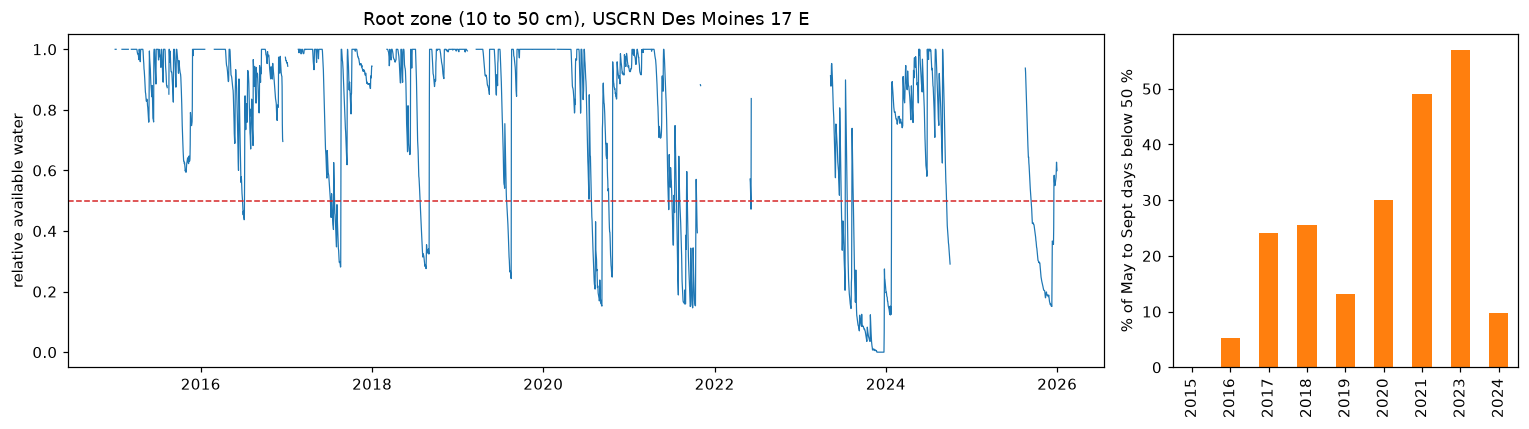

{2015: 0, 2016: 5, 2017: 24, 2018: 25, 2019: 13, 2020: 30, 2021: 49, 2023: 57, 2024: 10} | seasons left out (too few days): [2022, 2025]


In [7]:
lim = ptf["USCRN Des Moines 17 E"]  # limits under the USCRN station
layer = {10: "5-15cm", 20: "15-30cm", 50: "30-60cm"}  # sensor depth -> SoilGrids layer
raw = sum(sm.soil_water_status(daily[f"sm_{d}"], lim.loc[g, "wilting_point"], lim.loc[g, "field_capacity"])
          for d, g in layer.items()) / 3  # mean relative available water of the three sensors
raw = pd.Series(np.asarray(raw), index=daily.index)  # daily series
season = raw[(raw.index.month >= 5) & (raw.index.month <= 9)].dropna()  # May to September days with data
n_days = season.groupby(season.index.year).size()  # observed days per season
dry = season.lt(0.5).groupby(season.index.year).mean() * 100  # share of observed days below 50 %
dry = dry[n_days >= 100]  # keep seasons with at least 100 of 153 days observed
fig, ax = plt.subplots(1, 2, figsize=(14, 4), gridspec_kw={"width_ratios": [3, 1]})  # series and bars
ax[0].plot(raw.index, raw, lw=0.8); ax[0].axhline(0.5, color="tab:red", ls="--", lw=1)  # 50 % line
ax[0].set_ylabel("relative available water"); ax[0].set_title("Root zone (10 to 50 cm), USCRN Des Moines 17 E")  # labels
dry.plot.bar(ax=ax[1], color="tab:orange"); ax[1].set_ylabel("% of May to Sept days below 50 %")  # yearly bars
ax[1].set_xlabel(""); plt.tight_layout(); plt.show()  # draw
print(dry.round(0).astype(int).to_dict(), "| seasons left out (too few days):", sorted(set(n_days.index) - set(dry.index)))  # values

The years differ sharply: in 2023 the root zone spent 57 % of the observed growing season days
below 50 % of available water, in 2021 49 %, while 2015 and 2016 hardly dropped below it.
Seasons with large gaps (the 2022 outage) are left out because a share of a few observed days would be
misleading. The chapter's drought notebook (25) maps these dry seasons across the region from SMAP.

## Unit conversions and the Topp equation

A gravimetric sample, a degree of saturation from a scatterometer and a TDR reading all describe
the same soil water. The Topp et al. (1980) cubic relates the apparent permittivity measured by TDR
to volumetric water content for most mineral soils.

In [8]:
rho_b = float(prof["SCAN Ames"].loc["0-5cm", "bdod"])  # SoilGrids bulk density at the surface (g/cm3)
w = 0.20  # a gravimetric sample (g/g)
theta = float(sm.volumetric_from_gravimetric(w, rho_b))  # volumetric water content
phi = float(sm.porosity_from_bulk_density(rho_b))  # porosity from bulk density
print(f"bulk density {rho_b:.2f} g/cm3: w = {w} g/g -> theta = {theta:.3f} m3/m3; "
      f"porosity {phi:.3f}; degree of saturation {float(sm.degree_of_saturation(theta, phi)):.2f}")  # conversions
print(f"an ASCAT-style 62 % saturation is {float(sm.saturation_to_volumetric(62.0, phi)):.3f} m3/m3")  # saturation to volumetric
eps = sm.topp_inverse(np.array([0.05, 0.15, 0.25, 0.35, 0.45]))  # permittivity of each water content
display(pd.DataFrame({"theta": [0.05, 0.15, 0.25, 0.35, 0.45], "apparent permittivity": eps,
                      "back with topp": sm.topp(eps)}).round(3))  # round trip

bulk density 1.49 g/cm3: w = 0.2 g/g -> theta = 0.298 m3/m3; porosity 0.440; degree of saturation 0.68
an ASCAT-style 62 % saturation is 0.273 m3/m3


,theta,apparent permittivity,back with topp
0,0.05,3.790,0.05
1,0.15,8.113,0.15
2,0.25,13.408,0.25
3,0.35,20.375,0.35
4,0.45,30.767,0.45


Water dominates permittivity: about 80 for liquid water against 3 to 5 for dry soil minerals. The
apparent permittivity of soil therefore rises from about 4 to 31 as soil moisture goes from 0.05 to
0.45 m3 m-3. This contrast is what microwave remote sensing exploits, and it is the subject of the next
notebook.

## Summary and exercises

- Volumetric water content is the common currency; degree of saturation and relative available
  water need porosity, field capacity and wilting point, which texture can estimate.
- At the Iowa station near-surface soil moisture swings between about 0.16 and 0.41 m3 m-3, while the
  100 cm layer stays near 0.48 to 0.52; in situ records have gaps too.
- The 83 mm storm of 2 July 2024 reached 50 cm within the hour through preferential flow, but the
  rise shrank from 0.12 m3 m-3 at 5 cm to almost nothing at 100 cm.
- Two stations 60 km apart correlate only at about 0.4 day to day, and one reports values above
  porosity that need screening.
- SoilGrids texture with the Saxton and Rawls functions gives limits of the right magnitude, but the
  near-surface soil dries below the estimated wilting point and the subsoil is wetter than estimated.
- The share of growing season days below 50 % of available water separates drought seasons (2021,
  2023) from wet ones.

**Exercises**

1. Repeat the storm analysis for the 20 May 2024 event. Is the response faster or slower than in
   July, and why might the antecedent moisture matter?
2. Compute the relative available water at SCAN Ames with its own SoilGrids profile. Which station
   had more stress days in 2023?
3. Change the organic matter in `sm.saxton_rawls` from the SoilGrids value to 1 % and to 4 %.
   How much do field capacity and plant available water change?
4. Use `sm.degree_of_saturation` with the pedotransfer saturation to express the USCRN 5 cm
   record as degree of saturation. What fraction of days is above 0.9?